### Tests of Tang model for mmWave from:
https://ieeexplore.ieee.org/document/9837936

W. Tang et al., "Path Loss Modeling and Measurements for Reconfigurable Intelligent Surfaces in the Millimeter-Wave Frequency Band," in IEEE Transactions on Communications, vol. 70, no. 9, pp. 6259-6276, Sept. 2022, doi: 10.1109/TCOMM.2022.3193400

In [1]:
# To get the parent path for the notebook
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

In [2]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

import plotly.io as pio
pio.renderers.default = 'notebook_connected' # 'browser' for avoid error but shown in the browser
import plotly.graph_objects as go

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

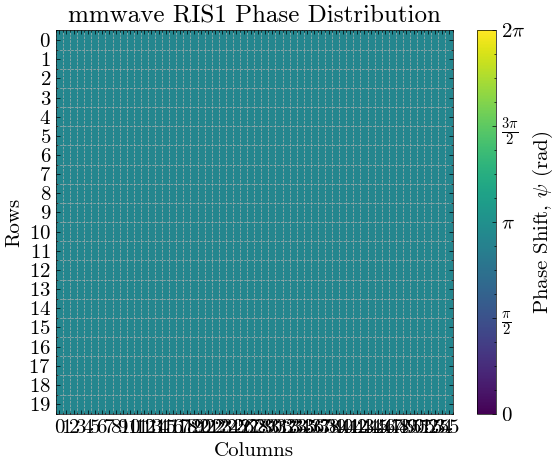

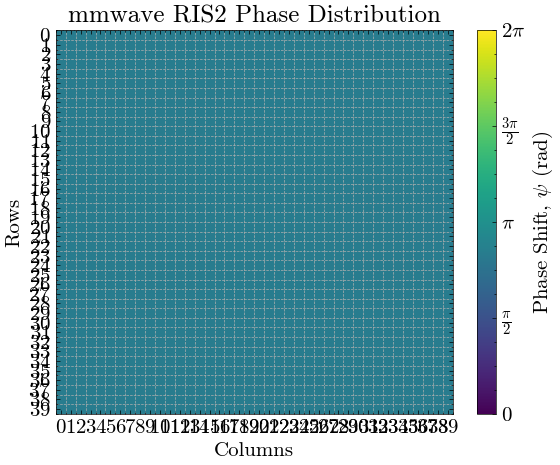

In [3]:
# Create RIS
f = 27e9
lam = c/f

mmwave_ris1 = RIS(center=[0,0,0],boresight='z',Ncol=56,Nrow=20,delta_h=1.4e-3,delta_v=2.8e-3,dx=1.4e-3,dy=2.8e-3,fc=f,radiation_factor=1,phase_shifts_dict={"0": np.deg2rad(165),"1": 0},att_dict={"0": 0.9,"1": 0.7}, name="mmwave RIS1")
mmwave_ris1.plot_phase_dist()

f = 33e9
lam = c/f

mmwave_ris2 = RIS(center=[0,0,0],boresight='z',Ncol=40,Nrow=40,delta_h=3.8e-3,delta_v=3.8e-3,dx=3.8e-3,dy=3.8e-3,fc=f,radiation_factor=1,phase_shifts_dict={"0": np.deg2rad(150),"1": 0},att_dict={"0": 0.8,"1": 0.8},name="mmwave RIS2")
mmwave_ris2.plot_phase_dist()

In [4]:
# Antenna params
# G_dBi_27ghz = 20.4
# G_dBi_33ghz = 21.1

# Adding the losses of their RF cables (Gline)
G_dBi_27ghz_A = 2.9 / 2 + 10 # Gt + Gr + Gline = 2.9 dB in setup A, compensating the Ptx it is + 20 dBm
G_dBi_27ghz_B = 24 / 2 + 10 # Gt + Gr + Gline = 24 dB in setup B, compensating the Ptx it is + 20 dBm
G_dBi_33ghz_B = 22 / 2 + 10 # Gt + Gr + Gline = 22 dB in setup B, compensating the Ptx it is + 20 dBm

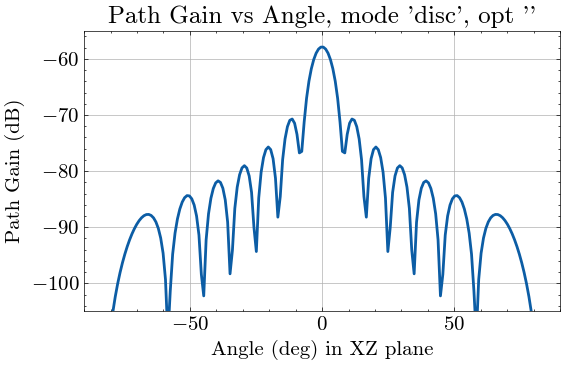

In [5]:
# Fig. 9:
# mmwave_RIS1, f = 27e9, P_tx = 20 dBm, system A
# d_tx = 1.3 m, theta_tx = 0, phi_tx = 0
# d_rx = 2.6 m, theta_rx in [0, 90], phi_tx = [0, 180] --> all the angles in the horizontal plane

# Fixed position for TX:
tx_pos = sph2cart([1.3, 0, 0])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_A)

# Auxiliar fixed position for RX (RIS not optimized so not needed):
rx_pos = sph2cart([2.6, 0, 0])
rx_antenna = Antenna(position=rx_pos, gain_dbi=G_dBi_27ghz_A)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')

# With default state (all "0" states) obtain the RX power at all the positions of the RX
channel.plot_path_gain_angle(r=2.6, Nr=200, axis='x', vmin=-105, vmax=-55)

Text(0.5, 1.0, 'Fig. 11d')

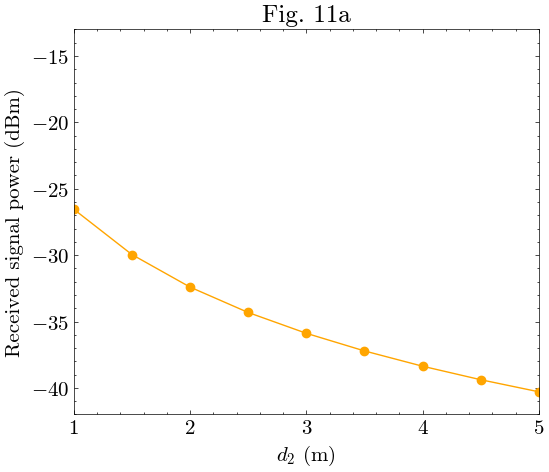

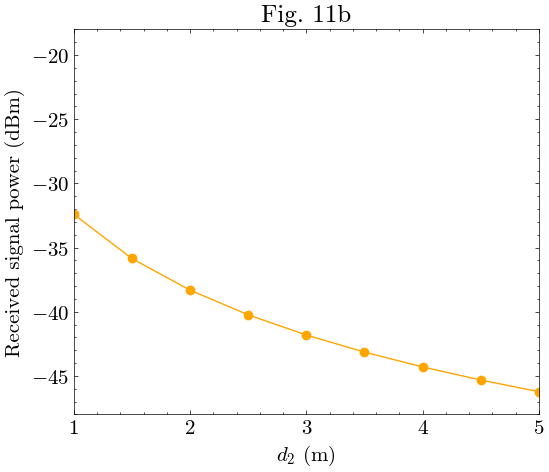

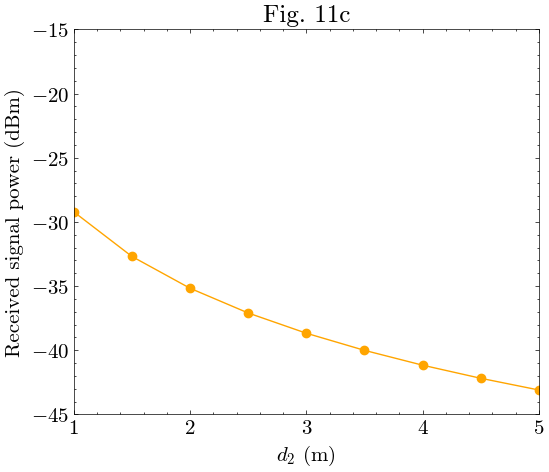

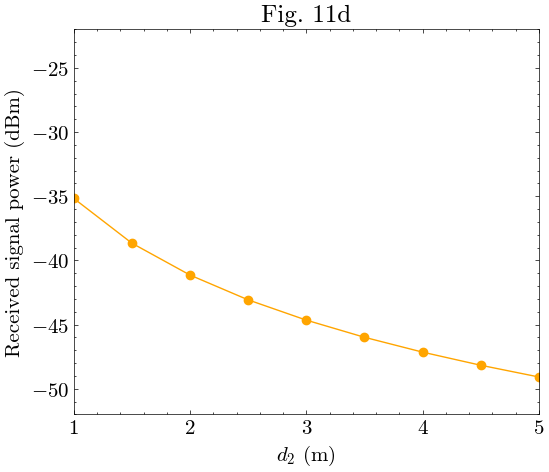

In [6]:
# Fig. 11:
# mmwave_RIS1, f = 27e9, P_tx = 20 dBm, specular, system B
# a) d_tx = 1 m, d_rx in [1, 5] m, theta_tx = theta_rx = 10 deg, phi_tx = 0, phi_rx = 180
# b) d_tx = 2 m, d_rx in [1, 5] m, theta_tx = theta_rx = 10 deg, phi_tx = 0, phi_rx = 180
# c) d_tx = 1 m, d_rx in [1, 5] m, theta_tx = theta_rx = 45 deg, phi_tx = 0, phi_rx = 180
# d) d_tx = 2 m, d_rx in [1, 5] m, theta_tx = theta_rx = 45 deg, phi_tx = 0, phi_rx = 180

# a)
# Fixed position for TX:
tx_pos = sph2cart([1, 0, 10])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_B)

rx_positions = np.zeros((9,3))
for kk in range(9):
    rx_positions[kk] = sph2cart([1 + kk*0.5, 180, 10])

# Auxiliar fixed position for RX (RIS not optimized so not needed):
rx_antenna = Antenna(position=rx_positions[0], gain_dbi=G_dBi_27ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(1,5.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([1, 5])
plt.xlabel("$d_2$ (m)")
plt.ylim([-42, -13])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 11a")

# b)
# Fixed position for TX:
tx_pos = sph2cart([2, 0, 10])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(1,5.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([1, 5])
plt.xlabel("$d_2$ (m)")
plt.ylim([-48, -18])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 11b")

# c)
# Fixed position for TX:
tx_pos = sph2cart([1, 0, 45])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_B)

rx_positions = np.zeros((9,3))
for kk in range(9):
    rx_positions[kk] = sph2cart([1 + kk*0.5, 180, 45])

# Auxiliar fixed position for RX (RIS not optimized so not needed):
rx_antenna = Antenna(position=rx_positions[0], gain_dbi=G_dBi_27ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(1,5.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([1, 5])
plt.xlabel("$d_2$ (m)")
plt.ylim([-45, -15])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 11c")

# d)
# Fixed position for TX:
tx_pos = sph2cart([2, 0, 45])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(1,5.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([1, 5])
plt.xlabel("$d_2$ (m)")
plt.ylim([-52, -22])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 11d")

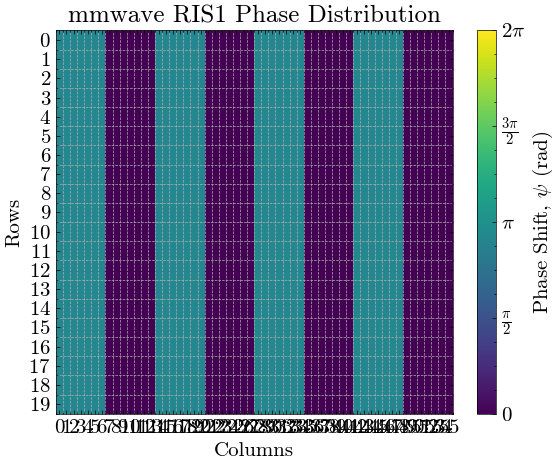

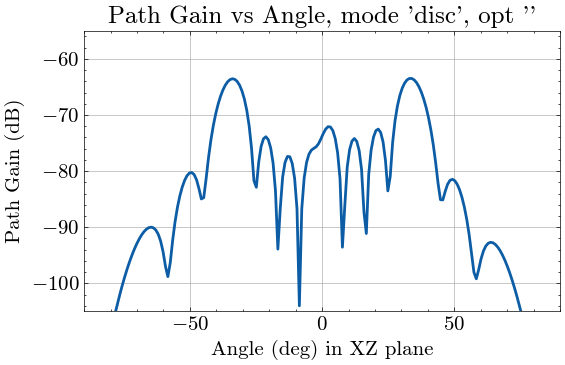

In [ ]:
# Fig. 12:
# mmwave_RIS1, f = 27e9, P_tx = 20 dBm, intelligent reflection, system A
# d_tx = 1.3 m, theta_tx = 0, phi_tx = 0
# d_rx = 2.6 m, thata_rx in [0, 90], phi_rx = [0, 180] --> all the angles in the horizontal plane

# Intelligent refletion here is obtained by a stripe code where (m in [1, 56]):
# -     code state "0" is applied when mod(m,14) in [1,7]
# -     code state "1" is applied when mod(m,14) not in [1,7]

# Create TX and RX
tx_pos = sph2cart([1.3, 0, 0])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_27ghz_A)

# Auxiliar fixed position for RX (RIS not optimized because of it so not needed):
rx_pos = sph2cart([2.6, 0, 0])
rx_antenna = Antenna(position=rx_pos, gain_dbi=G_dBi_27ghz_A)

# Give the stripe code to the RIS and create the channel
stripe_code = np.zeros((mmwave_ris1.Nrow, mmwave_ris1.Ncol))
stripe_code[:, 7:14] = 1  # Apply state "1" in columns 7 to 13
stripe_code[:, 21:28] = 1  # Apply state "1" in columns 21 to 27
stripe_code[:, 35:42] = 1 # Apply state "1" in columns 35 to 41
stripe_code[:, 49:56] = 1 # Apply state "1" in columns 49 to 55

mmwave_ris1.set_all_state(stripe_code)

mmwave_ris1.plot_phase_dist()

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris1, model='Tang_general')
# With actual state (stripe code) obtain the RX power at all the positions of the RX
channel.plot_path_gain_angle(r=2.6, Nr=200, axis='x', vmin=-105, vmax=-55)



# Reset RIS to default state
mmwave_ris1.reset_ris()

Text(0.5, 1.0, 'Fig. 13b : TX on NF gives problems')

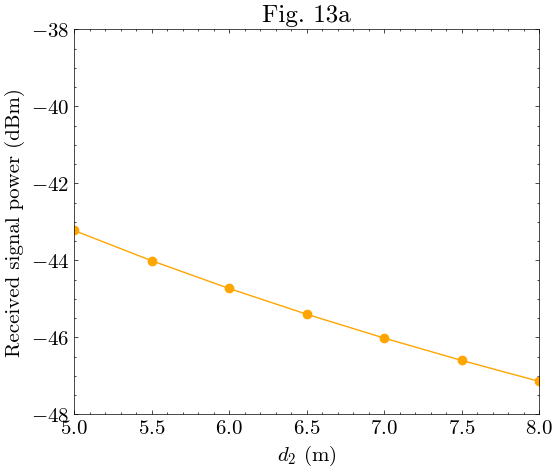

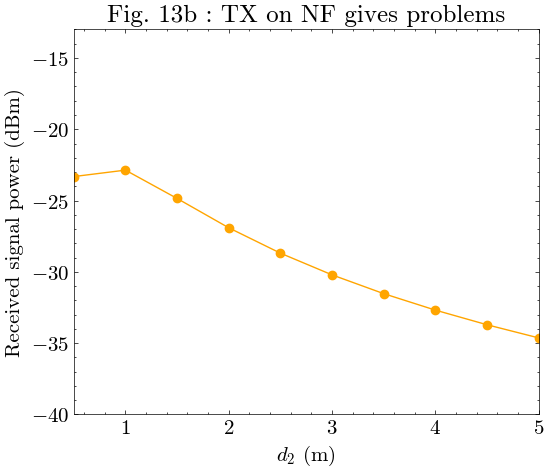

In [17]:
# Fig 13.
# mmwave_RIS2, f = 33e9, P_tx = 20 dBm, specular reflection, system B

# a) 
    # d_tx = 5 m, theta_tx = 10, phi_tx = 0
    # d_rx in [5, 8] m, theta_rx = 10, phi_rx = 180

# b) 
    # d_tx = 0.25 m, theta_tx = 10, phi_tx = 0
    # d_rx in [0.5, 5] m, theta_rx = 10, phi_rx = 180

# a)
# Fixed position for TX:
tx_pos = sph2cart([5, 0, 10])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_33ghz_B)

rx_positions = np.zeros((7,3))
for kk in range(7):
    rx_positions[kk] = sph2cart([5 + kk*0.5, 180, 10])

# Auxiliar fixed position for RX (RIS not optimized so not needed):
rx_antenna = Antenna(position=rx_positions[0], gain_dbi=G_dBi_33ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris2, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(5, 8.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([5, 8])
plt.xlabel("$d_2$ (m)")
plt.ylim([-48, -38])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 13a")

# b)
# Fixed position for TX:
tx_pos = sph2cart([0.25, 0, 10])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_33ghz_B)

rx_positions = np.zeros((10,3))
for kk in range(10):
    rx_positions[kk] = sph2cart([0.5 + kk*0.5, 180, 10])

# Auxiliar fixed position for RX (RIS not optimized so not needed):
rx_antenna = Antenna(position=[rx_positions[0]], gain_dbi=G_dBi_33ghz_B)

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris2, model='Tang_general')

pg = channel.path_gain_multrx(rx_positions)

plt.figure(figsize=(6, 5))
plt.plot(np.arange(0.5, 5.5, 0.5), 10*np.log10(pg), marker='o',color='orange')
plt.xlim([0.5, 5])
plt.xlabel("$d_2$ (m)")
plt.ylim([-40, -13])
plt.ylabel("Received signal power (dBm)")
plt.title("Fig. 13b : TX on NF gives problems")


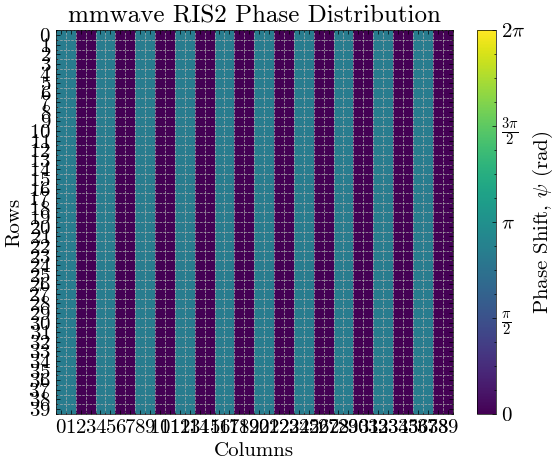

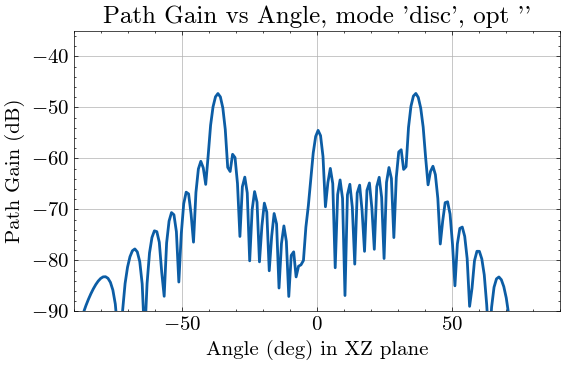

In [32]:
# Fig. 14:
# mmwave_RIS2, f = 33e9, P_tx = 20 dBm, intelligent reflection, system B
# d_tx = 5 m, theta_tx = 00, phi_tx = 0
# d_rx = 5 m, theta_rx in [0, 90], phi_rx = [0, 180] --> all the angles in the horizontal plane

# Intelligent refletion here is obtained by a stripe code where (m in [1, 40]):
# -     code state "0" is applied when mod(m,4) in [1, 2]
# -     code state "1" is applied when mod(m,4) not in [1, 2]

# Create TX and RX
tx_pos = sph2cart([5, 0, 0])
tx_antenna = Antenna(position=tx_pos, gain_dbi=G_dBi_33ghz_B)

# Auxiliar fixed position for RX (RIS not optimized because of it so not needed):
rx_pos = sph2cart([5, 0, 0])
rx_antenna = Antenna(position=rx_pos, gain_dbi=G_dBi_33ghz_B)

# Give the stripe code to the RIS and create the channel
stripe_code = np.zeros((mmwave_ris2.Nrow, mmwave_ris2.Ncol))

for col in range(mmwave_ris2.Ncol):
    if col % 4 == 2 or col % 4 == 3:
        stripe_code[:, col] = 1  # Apply state "1"

mmwave_ris2.set_all_state(stripe_code)
mmwave_ris2.plot_phase_dist()

# Create channel
channel = tx_ris_rx_channel(tx_antenna=tx_antenna, rx_antenna=rx_antenna, ris=mmwave_ris2, model='Tang_general')
# With actual state (stripe code) obtain the RX power at all the positions of the RX
channel.plot_path_gain_angle(r=5, Nr=200, axis='x', vmin=-90, vmax=-35)